# Physical metrics from coordinates

Differentiate positions, accumulate workload and inspect acceleration efforts using explicit calculations.

Download the bounded real sample first with `python scripts/download_data.py` from the repository root. Run cells in order. Each notebook can start a fresh kernel. Only data ingestion and pitch drawing use shared helpers; calculations below use NumPy/pandas/SciPy directly. Raw files remain excluded from Git. The sample contains one partial first half, so supervised-model training requires additional labeled matches for meaningful evaluation.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'workshop.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from workshop import load_data, pitch  # ingestion and drawing only; methods below are explicit
dataset, wide, tracking, metadata, events, phases, raw = load_data()
tracking = tracking.sort_values(['player_id','period_id','frame_id']).copy()
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
observed = tracking.dropna(subset=['x','y'])
frame_id = int(observed.groupby(['period_id','frame_id']).size().loc[lambda s:s.eq(22)].index[20][1])
snapshot = observed[observed.frame_id.eq(frame_id)].copy()
keepers = {str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels = {str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
print('Real match 1925299; loaded frames:', wide.shape[0], '| illustrative frame:', frame_id)

Real match 1925299; loaded frames: 6153 | illustrative frame: 61


## Smooth and differentiate within continuous segments
Compute velocity from coordinate gradients and actual timestamps. Split at missing data, gaps and periods. Gaussian smoothing here is retrospective and symmetric: live prediction needs a causal alternative or latency allowance. Exclude filter boundaries. [DataBallPy](https://databallpy.readthedocs.io/en/main/), [SkillCorner acceleration definitions](https://skillcorner.com/articles/new-feature-explosive-accelerations) and [SkillCorner peak-speed definitions](https://skillcorner.com/articles/skillcorner-releases-new-peak-velocity-metric) provide the methodological context; our estimates do not recreate proprietary processing.

In [2]:
from scipy.ndimage import gaussian_filter1d
motion=tracking.copy();motion[['vx','vy','speed_kmh','accel']]=np.nan
for _,g in motion.groupby(['player_id','period_id']):
    valid=g[['x','y']].notna().all(axis=1)
    splits=(~valid|~valid.shift(fill_value=False)|g.frame_id.diff().ne(1)|g.seconds.diff().le(0)).cumsum()
    for _,s in g[valid].groupby(splits[valid]):
        if len(s)<20:continue
        xy=gaussian_filter1d(s[['x','y']].to_numpy(),sigma=1.5,axis=0,mode='nearest')
        v=np.gradient(xy,s.seconds.to_numpy(),axis=0);speed=np.linalg.norm(v,axis=1)
        acceleration=np.gradient(speed,s.seconds.to_numpy())
        v[:5]=np.nan;v[-5:]=np.nan;speed[:5]=np.nan;speed[-5:]=np.nan
        acceleration[:6]=np.nan;acceleration[-6:]=np.nan
        motion.loc[s.index,['vx','vy']]=v;motion.loc[s.index,'speed_kmh']=speed*3.6;motion.loc[s.index,'accel']=acceleration
display(motion[['player_id','frame_id','vx','vy','speed_kmh','accel']].dropna().head())

,player_id,frame_id,vx,vy,speed_kmh,accel
67689,11897,46,-0.247765,0.174801,1.091594,0.606738
67690,11897,47,-0.290122,0.221082,1.313129,0.610326
67691,11897,48,-0.324011,0.275472,1.531029,0.607658
67692,11897,49,-0.350501,0.337086,1.750643,0.646995
67693,11897,50,-0.378850,0.405152,1.996865,0.738426


## Distance, intensity bands and coverage
Integrate trapezoidally over valid neighboring speed estimates. Allocate intervals to intensity bands by mean interval speed. This differs slightly from frame-rectangle conventions; disclose the convention. The men's HSR and sprint thresholds here are 20 and 25 km/h. Report valid exposure and avoid scaling a partial sample into a full match.

,player_id,valid_s,distance_m,HSR_m,sprint_m,coverage,sample_peak_kmh
15,795530,599.0,1827.779733,127.104950,5.918825,0.973509,27.568458
20,966112,600.1,1782.537938,112.206502,0.000000,0.975297,24.897186
1,287934,599.1,1734.763138,133.898882,68.533104,0.973671,28.348777
12,560986,598.4,1673.156061,194.571831,59.046084,0.972534,29.551199
7,51694,596.7,1663.598835,89.350435,8.536913,0.969771,26.061642
13,560987,600.3,1662.790754,166.090654,22.804554,0.975622,29.110785
9,560983,601.5,1589.803595,148.280257,95.723360,0.977572,36.498076
8,560882,596.4,1589.280732,99.438639,19.340130,0.969283,26.348442
17,797298,599.1,1578.731245,149.828188,31.745373,0.973671,28.210902
4,51002,601.5,1568.436447,164.024403,0.000000,0.977572,25.000118


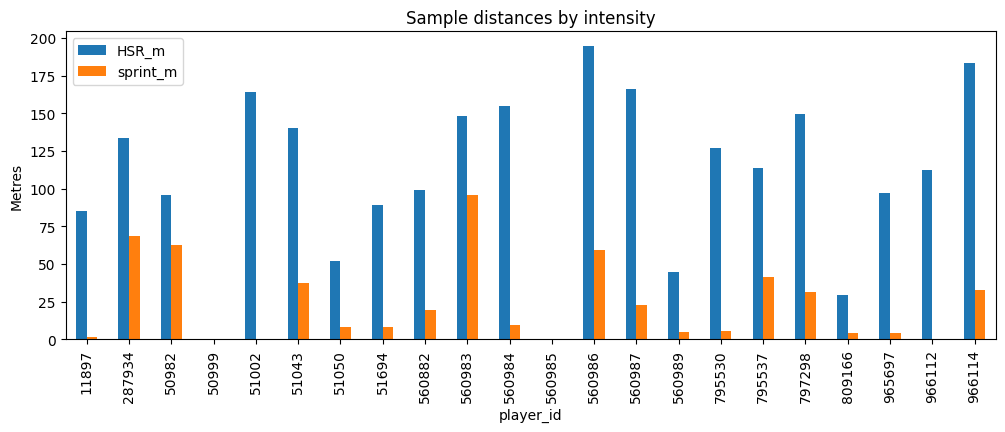

In [3]:
summaries=[]
for pid,g in motion.groupby('player_id'):
    g=g.sort_values(['period_id','frame_id']);dt=g.seconds.diff()
    valid=g.period_id.eq(g.period_id.shift())&g.frame_id.diff().eq(1)&dt.gt(0)&g.speed_kmh.notna()&g.speed_kmh.shift().notna()
    interval_speed=(g.speed_kmh+g.speed_kmh.shift())/2
    distance=interval_speed/3.6*dt
    summaries.append(dict(player_id=pid,valid_s=dt.where(valid).sum(),distance_m=distance.where(valid).sum(),HSR_m=distance.where(valid&interval_speed.ge(20)&interval_speed.lt(25)).sum(),sprint_m=distance.where(valid&interval_speed.ge(25)).sum(),coverage=valid.mean(),sample_peak_kmh=g.speed_kmh.max()))
summary=pd.DataFrame(summaries);display(summary.sort_values('distance_m',ascending=False).head(10))
summary.set_index('player_id')[['HSR_m','sprint_m']].plot.bar(figsize=(12,4),title='Sample distances by intensity');plt.ylabel('Metres');plt.show()

## Sprint efforts and signed acceleration
Consecutive speed at or above 25 km/h for at least one second defines an effort **in this notebook**. No short-gap merging. Signed scalar acceleration measures speeding up/braking, while vector acceleration also responds to direction changes.

,player_id,start_s,duration_s,peak_kmh
0,287934,133.4,3.5,27.431501
1,287934,364.3,4.0,28.348777
2,287934,673.0,1.1,27.390025
3,50982,134.0,4.8,29.822522
4,50982,186.1,1.2,26.187768


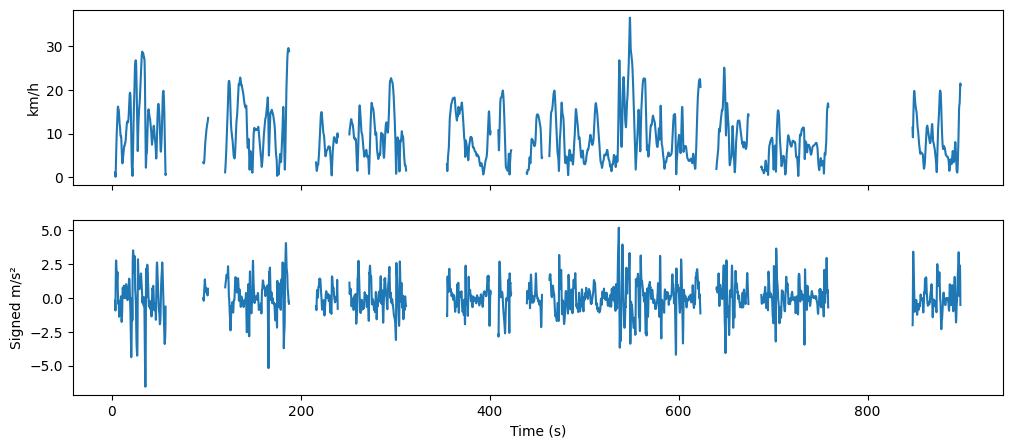

In [4]:
effort_rows=[]
for pid,g in motion.groupby('player_id'):
    g=g.sort_values(['period_id','frame_id']);active=g.speed_kmh.ge(25)
    segment=(active.ne(active.shift(fill_value=False))|g.frame_id.diff().ne(1)|g.period_id.ne(g.period_id.shift())).cumsum()
    for _,s in g[active].groupby(segment[active]):
        duration=s.seconds.iloc[-1]-s.seconds.iloc[0]+.1
        if duration>=1:effort_rows.append(dict(player_id=pid,start_s=s.seconds.iloc[0],duration_s=duration,peak_kmh=s.speed_kmh.max()))
display(pd.DataFrame(effort_rows,columns=['player_id','start_s','duration_s','peak_kmh']).head())
pid=summary.sort_values('sample_peak_kmh',ascending=False).player_id.iloc[0];g=motion[motion.player_id.eq(pid)]
fig,axs=plt.subplots(2,1,figsize=(12,5),sharex=True);axs[0].plot(g.seconds,g.speed_kmh);axs[0].set_ylabel('km/h');axs[1].plot(g.seconds,g.accel);axs[1].set(xlabel='Time (s)',ylabel='Signed m/s²');plt.show()

## Time from 9 to 20 / 25 km/h
Find consecutive rising-speed episodes, interpolate threshold crossings, and inspect durations. SkillCorner reports these metrics within **qualifying explosive accelerations** with additional production rules; the crossings below are not official Time to HSR / Time to Sprint. PSV-99 uses its specified activity population and cannot be replaced by an all-frame 99th percentile. Our sample peak is also distinct from validated production Peak Velocity.

In [5]:
def crossing_time(t,v,threshold):
    hits=np.flatnonzero((v[:-1]<threshold)&(v[1:]>=threshold))
    if not len(hits):return np.nan
    i=hits[0];return t[i]+(threshold-v[i])/(v[i+1]-v[i])*(t[i+1]-t[i])
crossings=[]
for pid,g in motion.groupby('player_id'):
    g=g.sort_values(['period_id','frame_id']);rising=g.accel.gt(0)&g.speed_kmh.notna()
    segment=(rising.ne(rising.shift(fill_value=False))|g.frame_id.diff().ne(1)|g.period_id.ne(g.period_id.shift())).cumsum()
    for _,s in g[rising].groupby(segment[rising]):
        if len(s)<3:continue
        t=s.seconds.to_numpy();v=s.speed_kmh.to_numpy();t9=crossing_time(t,v,9)
        for threshold in [20,25]:
            end=crossing_time(t,v,threshold)
            if np.isfinite(t9+end) and end>t9:crossings.append(dict(player_id=pid,target_kmh=threshold,seconds=end-t9))
display(pd.DataFrame(crossings,columns=['player_id','target_kmh','seconds']).head(12))
assert np.isclose(crossing_time(np.array([0,1]),np.array([0,20]),9),.45)

,player_id,target_kmh,seconds
0,11897,20,1.863908
1,11897,20,1.233406
2,11897,20,1.087799
3,11897,20,1.199481
4,287934,20,1.642657
5,287934,25,2.927325
6,287934,20,0.827738
7,287934,25,2.171694
8,287934,20,2.127895
9,287934,20,1.991966
